# Feature Reconstruction
Teacher-student feature reconstruction: a frozen ImageNet-pretrained backbone (teacher) extracts features,
a convolutional autoencoder (student) learns to reconstruct them on normal images only.
The anomaly map is `1 - cosine similarity` between teacher and reconstructed features.

In [1]:
from run_experiment import run_experiment_single_class, build_dataloaders, build_model
from utils.visualization import visualize_anomalies
from utils.helpers import get_device
from losses import CosineLoss
from pathlib import Path
import pandas as pd

W1112 11:02:59.494000 22356 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


## Baseline: single layer (`layer2`)
ResNet-18 `layer2` features (128 channels, 32x32 for 256x256 inputs), cosine loss, no blur on the anomaly map.

In [14]:
config = {

    'experiment_name': 'baseline_layer2',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data': True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': CosineLoss,
    'learning_rate': 1e-3,
    'num_epochs': 45,
    'patience': 5,

    # model
    'model_name': 'FeatureReconstructionModel',
    'backbone_name': 'resnet18',
    'feature_layers': ['layer2'],
    'output_dir': './experiments/feature_reconstruction',
}

DEVICE = get_device(config['device'])

In [16]:
# 2 easy classes (bottle, carpet) + 3 harder ones (capsule: small defects, screw: hardest class,
# transistor: misplaced/missing parts, i.e. more "semantic" anomalies)
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: CABLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'cable' on device: cuda


Evaluating: 100%|██████████| 10/10 [00:05<00:00,  1.69it/s]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'capsule' on device: cuda


Evaluating: 100%|██████████| 9/9 [00:05<00:00,  1.79it/s]



==============================  Starting class: CARPET  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'carpet' on device: cuda


Evaluating: 100%|██████████| 8/8 [00:04<00:00,  1.80it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 10/10 [00:03<00:00,  3.27it/s]



==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'bottle' on device: cuda


Evaluating: 100%|██████████| 6/6 [00:01<00:00,  3.26it/s]


,image_auroc,pixel_auroc,aupro
cable,0.9389,0.8887,0.7850
capsule,0.9126,0.9764,0.8786
carpet,0.9783,0.9726,0.9451
grid,0.8421,0.9298,0.7993
hazelnut,0.9875,0.9768,0.9320
leather,1.0000,0.9937,0.9868
metal_nut,0.9927,0.9150,0.8686
pill,0.8770,0.8905,0.8491
screw,0.8555,0.9759,0.9113
tile,0.9351,0.7733,0.5771


Loaded model weights from experiments\feature_reconstruction\baseline_layer2\capsule\checkpoints\best_model.pth


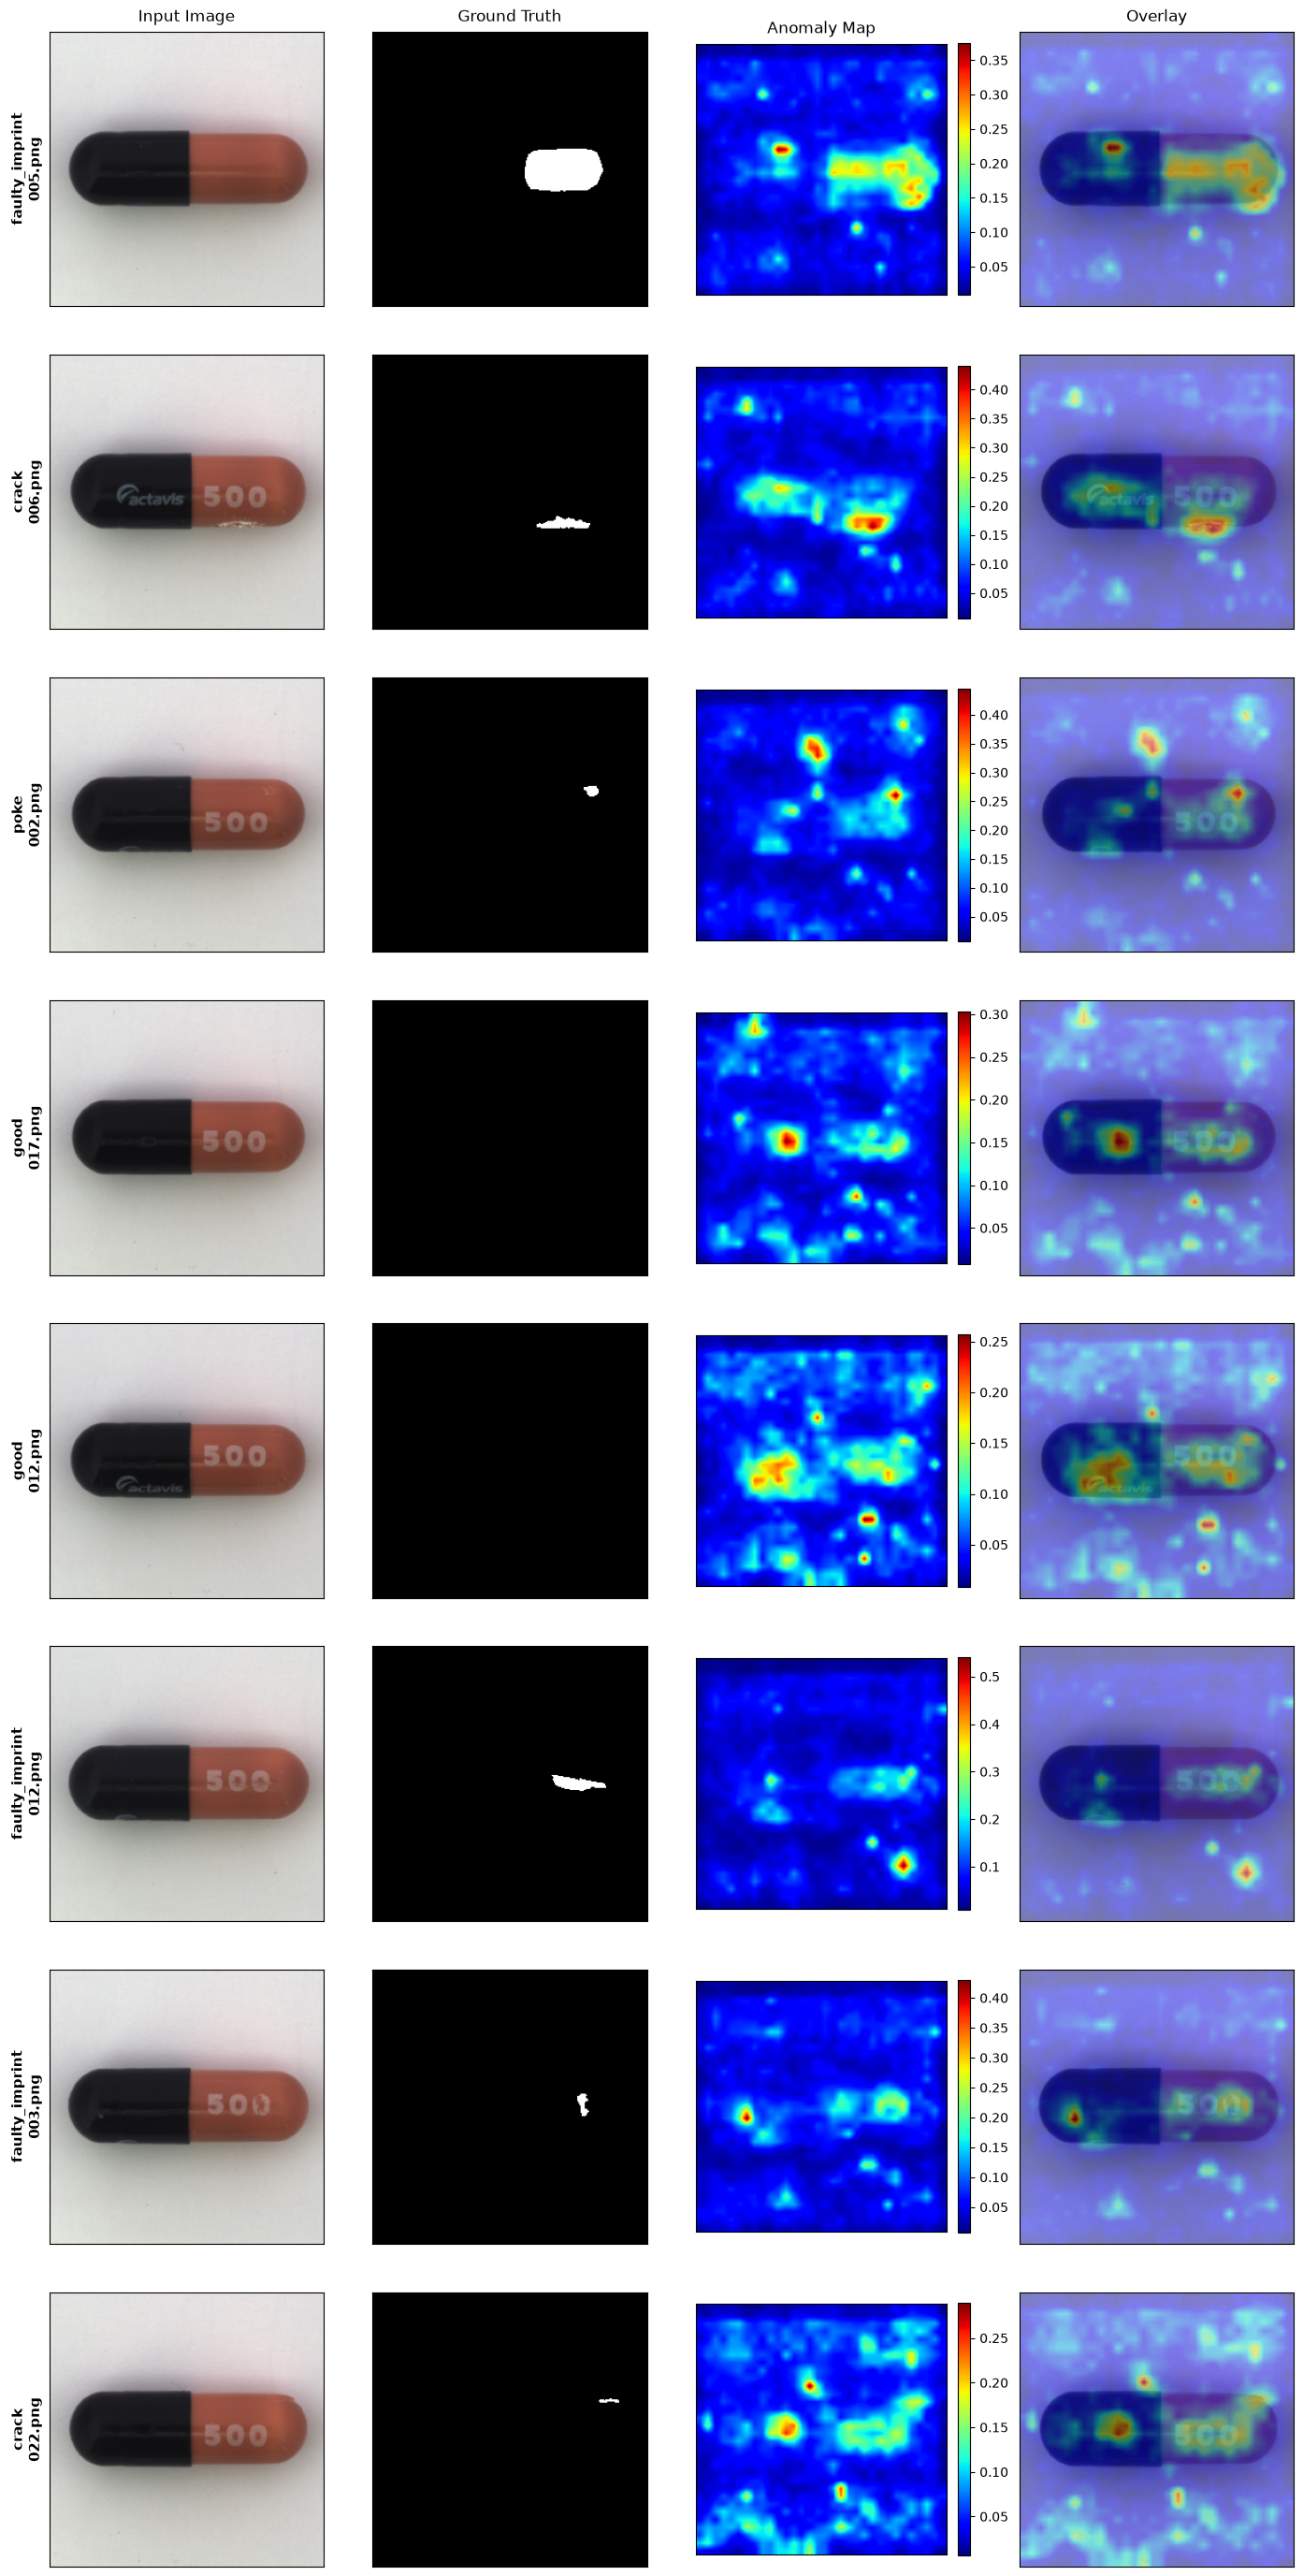

In [4]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = Path(config['output_dir']) / config['experiment_name'] / object_name / "checkpoints" / "best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
# visualize_reconstruction must stay False: the reconstruction is a feature map, not an RGB image
visualize_anomalies(model, test_loader, DEVICE)

## Ablation: single layer (`layer3`)
Same setup as the baseline, but with ResNet-18 `layer3` features (256 channels, 16x16): more semantic, lower resolution.

In [12]:
config = {

    'experiment_name': 'layer3',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data': True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': CosineLoss,
    'learning_rate': 1e-3,
    'num_epochs': 45,
    'patience': 5,

    # model
    'model_name': 'FeatureReconstructionModel',
    'backbone_name': 'resnet18',
    'feature_layers': ['layer3'],
    'output_dir': './experiments/feature_reconstruction',
}

DEVICE = get_device(config['device'])

In [13]:
# 2 easy classes (bottle, carpet) + 3 harder ones (capsule: small defects, screw: hardest class,
# transistor: misplaced/missing parts, i.e. more "semantic" anomalies)
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: CABLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'cable' on device: cuda


Evaluating: 100%|██████████| 10/10 [00:05<00:00,  1.71it/s]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'capsule' on device: cuda


Evaluating: 100%|██████████| 9/9 [00:05<00:00,  1.78it/s]



==============================  Starting class: CARPET  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'carpet' on device: cuda


Evaluating: 100%|██████████| 8/8 [00:04<00:00,  1.77it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 10/10 [00:03<00:00,  3.33it/s]



==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'bottle' on device: cuda


Evaluating: 100%|██████████| 6/6 [00:01<00:00,  3.35it/s]


,image_auroc,pixel_auroc,aupro
cable,0.9738,0.9696,0.8904
capsule,0.8361,0.9690,0.7957
carpet,0.9884,0.9890,0.9491
grid,0.8764,0.9502,0.8524
hazelnut,0.9914,0.9809,0.9127
leather,1.0000,0.9874,0.9700
metal_nut,0.9892,0.9375,0.8332
pill,0.8033,0.9355,0.8671
screw,0.8510,0.9241,0.7704
tile,0.9953,0.9186,0.7807


Loaded model weights from experiments\feature_reconstruction\baseline_layer2\capsule\checkpoints\best_model.pth


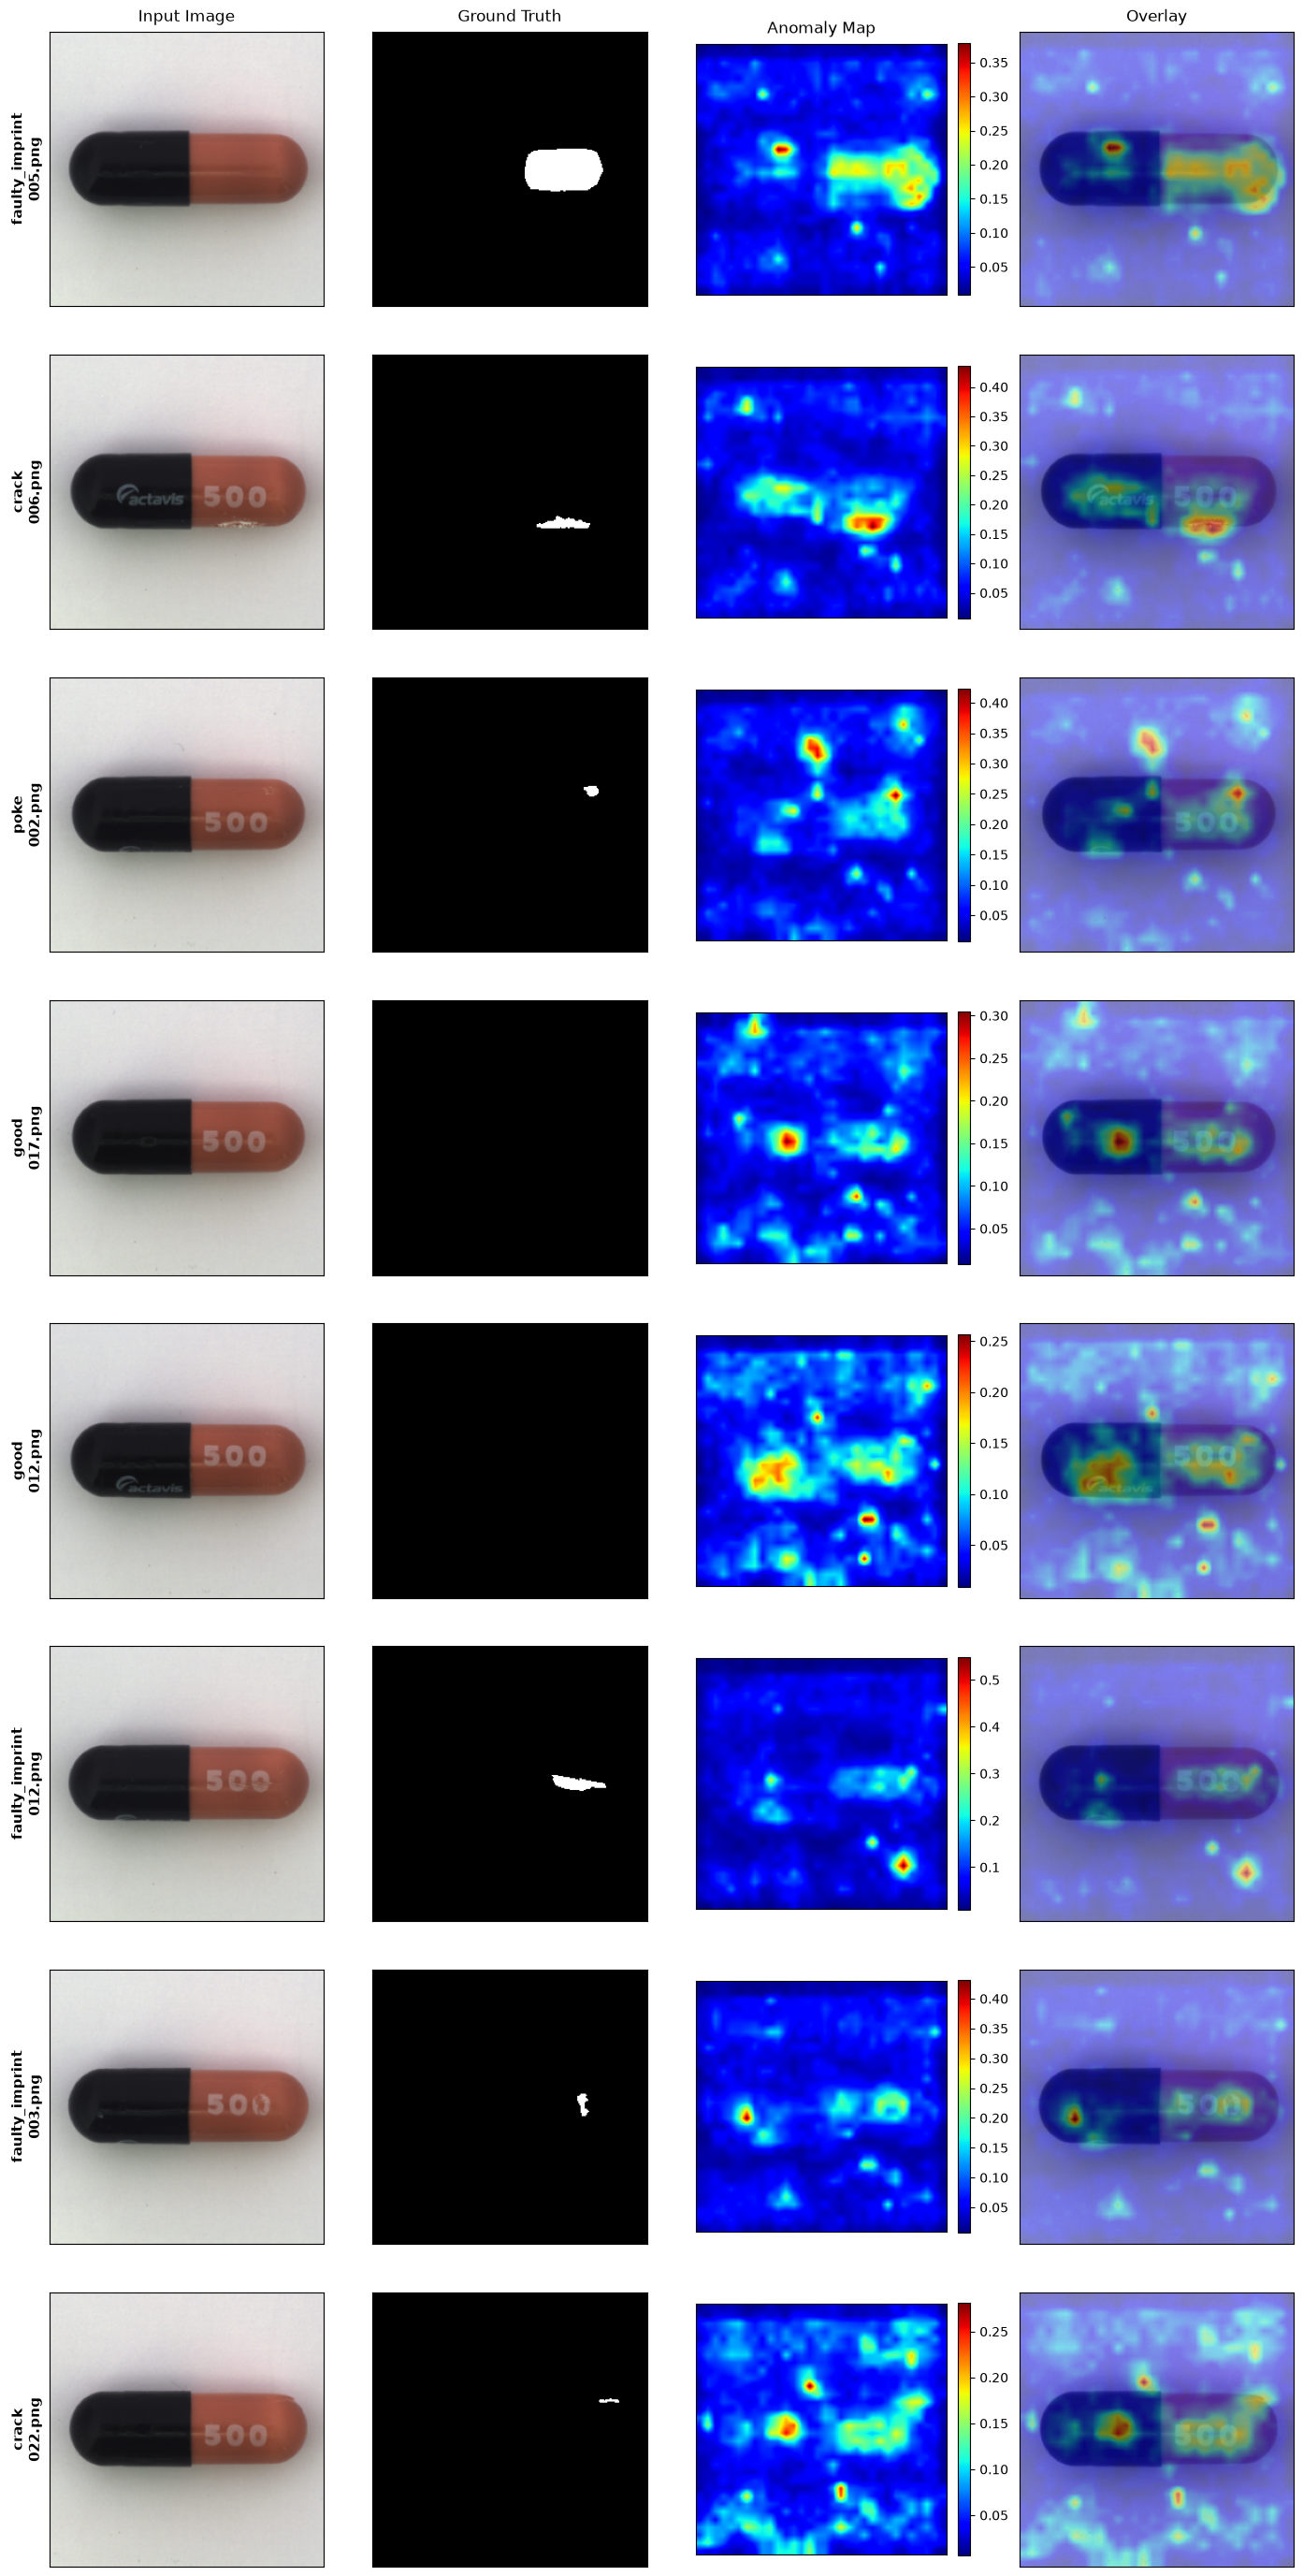

In [6]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = Path(config['output_dir']) / config['experiment_name'] / object_name / "checkpoints" / "best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
# visualize_reconstruction must stay False: the reconstruction is a feature map, not an RGB image
visualize_anomalies(model, test_loader, DEVICE)

## Ablation: `layer2 + layer3`, single cosine on the concatenated features
`layer3` is upsampled to 32x32 and concatenated with `layer2` (384 channels). Loss and anomaly map use a single
cosine on the concatenated vector: each layer weighs in proportion to its energy (||F_l||^2).
Control run of the loss ablation.

In [7]:
config = {

    'experiment_name': 'layer23_global',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data': True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': CosineLoss,
    'learning_rate': 1e-3,
    'num_epochs': 45,
    'patience': 5,

    # model
    'model_name': 'FeatureReconstructionModel',
    'backbone_name': 'resnet18',
    'feature_layers': ['layer2', 'layer3'],
    'per_layer_cosine': False,  # single cosine on the concatenated features
    'output_dir': './experiments/feature_reconstruction',
}

DEVICE = get_device(config['device'])

In [8]:
# 2 easy classes (bottle, carpet) + 3 harder ones (capsule: small defects, screw: hardest class,
# transistor: misplaced/missing parts, i.e. more "semantic" anomalies)
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: CABLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'cable' on device: cuda


Evaluating: 100%|██████████| 10/10 [00:07<00:00,  1.39it/s]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'capsule' on device: cuda


Evaluating: 100%|██████████| 9/9 [00:05<00:00,  1.64it/s]



==============================  Starting class: CARPET  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'carpet' on device: cuda


Evaluating: 100%|██████████| 8/8 [00:05<00:00,  1.55it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 10/10 [00:03<00:00,  3.13it/s]



==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'bottle' on device: cuda


Evaluating: 100%|██████████| 6/6 [00:02<00:00,  2.70it/s]


,image_auroc,pixel_auroc,aupro
cable,0.9410,0.9504,0.8758
capsule,0.8636,0.9795,0.8887
carpet,0.9831,0.9885,0.9638
grid,0.9106,0.9337,0.8386
hazelnut,0.9993,0.9838,0.9419
leather,1.0000,0.9931,0.9842
metal_nut,1.0000,0.9494,0.9103
pill,0.7938,0.9082,0.8639
screw,0.8338,0.9691,0.8914
tile,0.9845,0.8806,0.7256


Loaded model weights from experiments\feature_reconstruction\layer23_global\capsule\checkpoints\best_model.pth


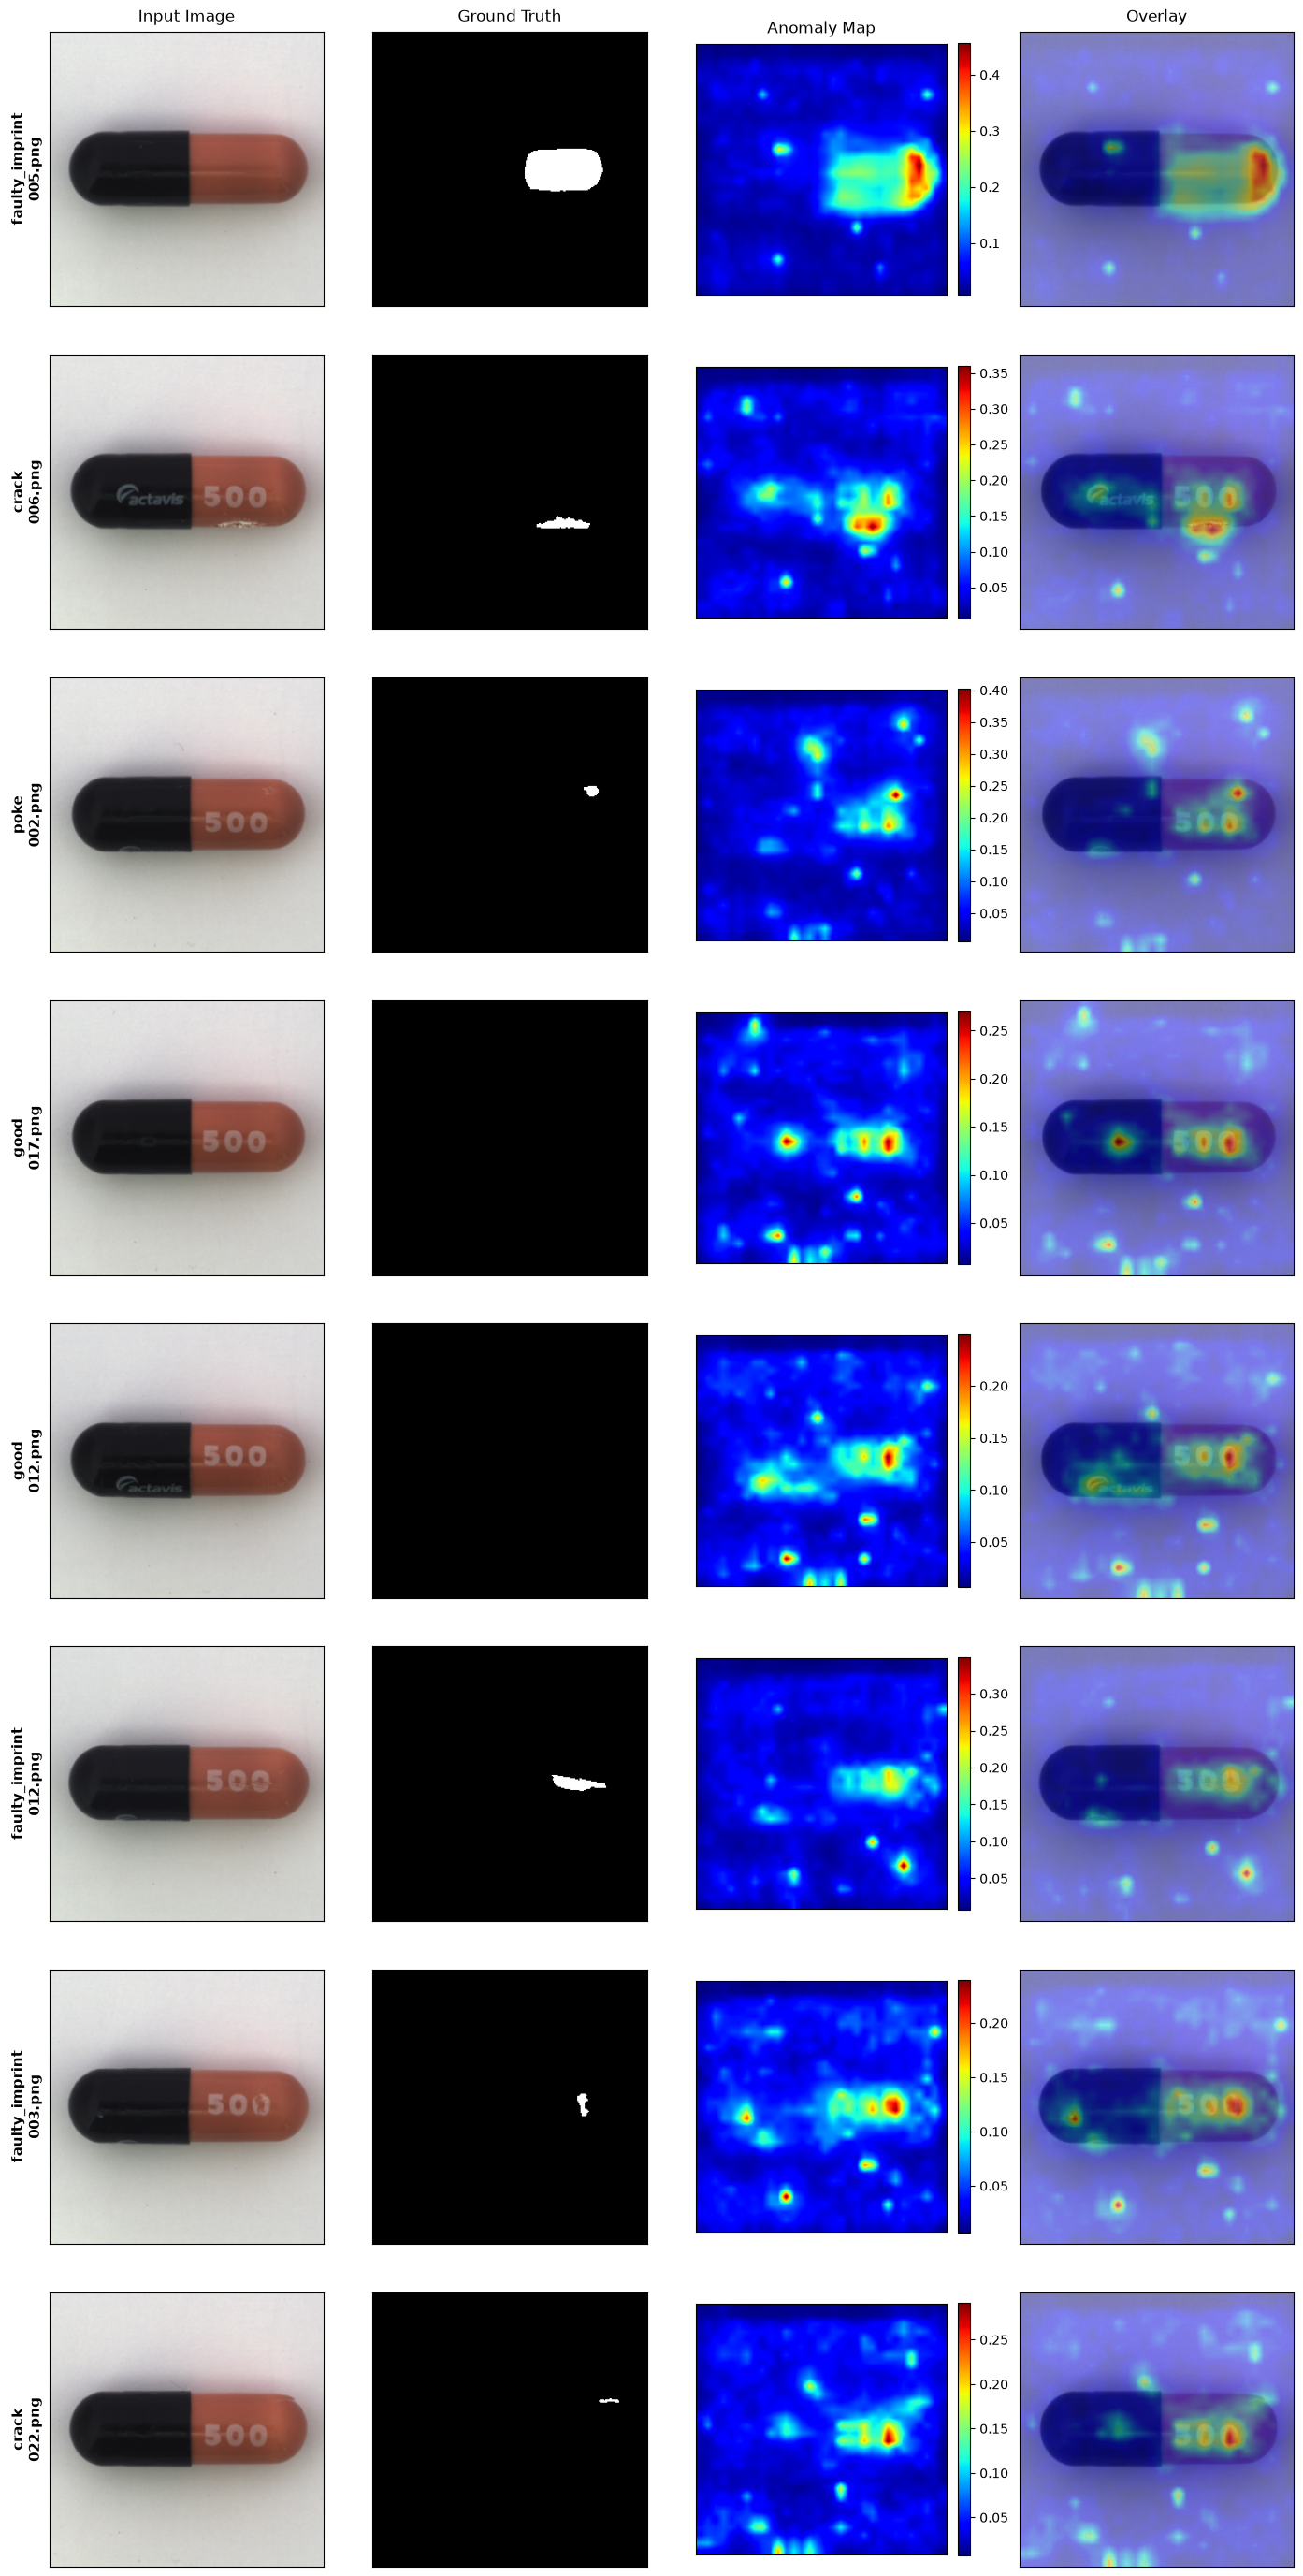

In [9]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = Path(config['output_dir']) / config['experiment_name'] / object_name / "checkpoints" / "best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
# visualize_reconstruction must stay False: the reconstruction is a feature map, not an RGB image
visualize_anomalies(model, test_loader, DEVICE)

## Ablation: `layer2 + layer3`, per-layer cosine
Same features as above, but loss and anomaly map compute one cosine per layer and average them,
so that both layers have the same weight.

In [10]:
config = {

    'experiment_name': 'layer23_per_layer',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data': True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': CosineLoss,
    'learning_rate': 1e-3,
    'num_epochs': 45,
    'patience': 5,

    # model
    'model_name': 'FeatureReconstructionModel',
    'backbone_name': 'resnet18',
    'feature_layers': ['layer2', 'layer3'],
    'per_layer_cosine': True,  # one cosine per layer, averaged
    'output_dir': './experiments/feature_reconstruction',
}

DEVICE = get_device(config['device'])

In [11]:
# 2 easy classes (bottle, carpet) + 3 harder ones (capsule: small defects, screw: hardest class,
# transistor: misplaced/missing parts, i.e. more "semantic" anomalies)
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: CABLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'cable' on device: cuda


Evaluating: 100%|██████████| 10/10 [00:05<00:00,  1.72it/s]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'capsule' on device: cuda


Evaluating: 100%|██████████| 9/9 [00:05<00:00,  1.78it/s]



==============================  Starting class: CARPET  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'carpet' on device: cuda


Evaluating: 100%|██████████| 8/8 [00:04<00:00,  1.76it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 10/10 [00:03<00:00,  3.11it/s]



==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.
Training FeatureReconstructionModel for class 'bottle' on device: cuda


Evaluating: 100%|██████████| 6/6 [00:01<00:00,  3.09it/s]


,image_auroc,pixel_auroc,aupro
cable,0.9430,0.9530,0.8800
capsule,0.8353,0.9755,0.8680
carpet,0.9936,0.9875,0.9632
grid,0.9607,0.9542,0.8863
hazelnut,0.9996,0.9821,0.9395
leather,1.0000,0.9934,0.9850
metal_nut,1.0000,0.9489,0.9050
pill,0.7818,0.9010,0.8379
screw,0.9176,0.9765,0.9102
tile,0.9906,0.8952,0.7564


In [ ]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = Path(config['output_dir']) / config['experiment_name'] / object_name / "checkpoints" / "best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
# visualize_reconstruction must stay False: the reconstruction is a feature map, not an RGB image
visualize_anomalies(model, test_loader, DEVICE)